# Supervivencia del Titanic: modelo y aplicación con Streamlit

Objetivo: predecir si un pasajero sobrevivió a partir de su clase, sexo, edad, familiares a bordo, tarifa y puerto de embarque, y publicar el modelo como aplicación web con Streamlit.

Reglas del notebook: el conjunto de test se aparta antes de explorar y se usa una sola vez al final; la elección del modelo se hace con validación cruzada solo sobre el entrenamiento; el preprocesado (imputación, escalado, codificación) va dentro de un Pipeline.

## Bloque 1: carga e inspección

Se carga el archivo y se miran forma, tipos, nulos, duplicados y balance de la clase. No se modifica ni se parte nada todavía.

In [1]:
import pandas as pd
import numpy as np

SEED = 42
RUTA = "../data/raw/titanic_train.csv"
df = pd.read_csv(RUTA)

print("Forma:", df.shape)
print(df.dtypes.to_string())
print("\nNulos por columna:")
print(df.isna().sum().to_string())
print("\nFilas duplicadas:", df.duplicated().sum(),
      "| PassengerId repetidos:", df["PassengerId"].duplicated().sum())
print("\nSupervivencia (proporción):")
print(df["Survived"].value_counts(normalize=True).round(3).to_string())
print("\nCardinalidad de texto:")
print(df[["Name", "Sex", "Ticket", "Cabin", "Embarked"]].nunique().to_string())

Forma: (891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str

Nulos por columna:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2

Filas duplicadas: 0 | PassengerId repetidos: 0

Supervivencia (proporción):
Survived
0    0.616
1    0.384

Cardinalidad de texto:
Name        891
Sex           2
Ticket      681
Cabin       147
Embarked      3


### Conclusiones del Bloque 1

- Hay 891 pasajeros y 12 columnas, sin filas duplicadas ni `PassengerId` repetidos.
- Sobrevivió el 38,4 % (342 de 891): predecir siempre "no sobrevivió" acierta el 61,6 %. Esa es la línea base que cualquier modelo debe superar.
- Faltan 177 edades (19,9 %), 687 cabinas (77,1 %) y 2 puertos de embarque; el resto de columnas está completo.
- `Name` (891 valores distintos) y `Ticket` (681) son casi identificadores, y `Cabin` está casi vacía: se descartan junto con `PassengerId`.
- Se usan `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare` y `Embarked`. Las edades y puertos faltantes se imputan dentro del Pipeline, para que solo se aprendan con el entrenamiento.

## Bloque 2: partición entrenamiento y prueba

Se aparta el 20 % de los pasajeros como prueba, estratificado por la clase y con semilla fija, antes de explorar nada. `Pclass` se trata como categoría (1, 2, 3) y no como número.

In [2]:
from sklearn.model_selection import train_test_split

NUM = ["Age", "SibSp", "Parch", "Fare"]
CAT = ["Pclass", "Sex", "Embarked"]
X = df[NUM + CAT]
y = df["Survived"]

X_ent, X_test, y_ent, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Entrenamiento:", X_ent.shape, "| Prueba:", X_test.shape)
print(pd.DataFrame({"entrenamiento": y_ent.value_counts(normalize=True),
                    "prueba": y_test.value_counts(normalize=True)}).round(3))
print("\nNulos en entrenamiento:\n", X_ent.isna().sum().to_string())

Entrenamiento: (712, 7) | Prueba: (179, 7)
          entrenamiento  prueba
Survived                       
0                 0.617   0.615
1                 0.383   0.385

Nulos en entrenamiento:
 Age         137
SibSp         0
Parch         0
Fare          0
Pclass        0
Sex           0
Embarked      2


### Conclusiones del Bloque 2

- La partición dejó 712 pasajeros de entrenamiento y 179 de prueba, con la proporción de supervivientes casi idéntica (38,3 % y 38,5 %).
- El test es pequeño: unos 69 supervivientes, así que un solo pasajero mueve el resultado más de medio punto. Se tendrá en cuenta al interpretar el resultado final.
- Las únicas variables con nulos son `Age` (137 en entrenamiento) y `Embarked` (2); se imputarán dentro del Pipeline.

## Bloque 3: exploración (solo entrenamiento)

Se mira qué variables mueven la supervivencia, si la falta de edad se relaciona con ella y cómo se distribuyen las variables numéricas. La prueba no se toca.

Supervivencia por Sex:
         tasa    n
Sex               
female  0.743  253
male    0.185  459 

Supervivencia por Pclass:
         tasa    n
Pclass            
1       0.649  171
2       0.447  150
3       0.243  391 

Supervivencia por Embarked:
           tasa    n
Embarked            
C         0.561  139
Q         0.436   55
S         0.328  516 

Supervivencia por sexo y clase:
Pclass      1      2      3
Sex                        
female  0.975  0.914  0.500
male    0.370  0.152  0.135 

Supervivencia por tramo de edad:
            tasa    n
Age                  
(0, 12]    0.600   55
(12, 18]   0.415   53
(18, 40]   0.382  346
(40, 60]   0.410  105
(60, 100]  0.188   16 

Supervivencia con edad conocida (False) o faltante (True):
        tasa    n
Age              
False  0.405  575
True   0.292  137 

Supervivencia por familiares a bordo (4 = 4 o más):
    tasa    n
0  0.300  434
1  0.550  129
2  0.623   77
3  0.727   22
4  0.160   50 

Variables numéricas:
       count  

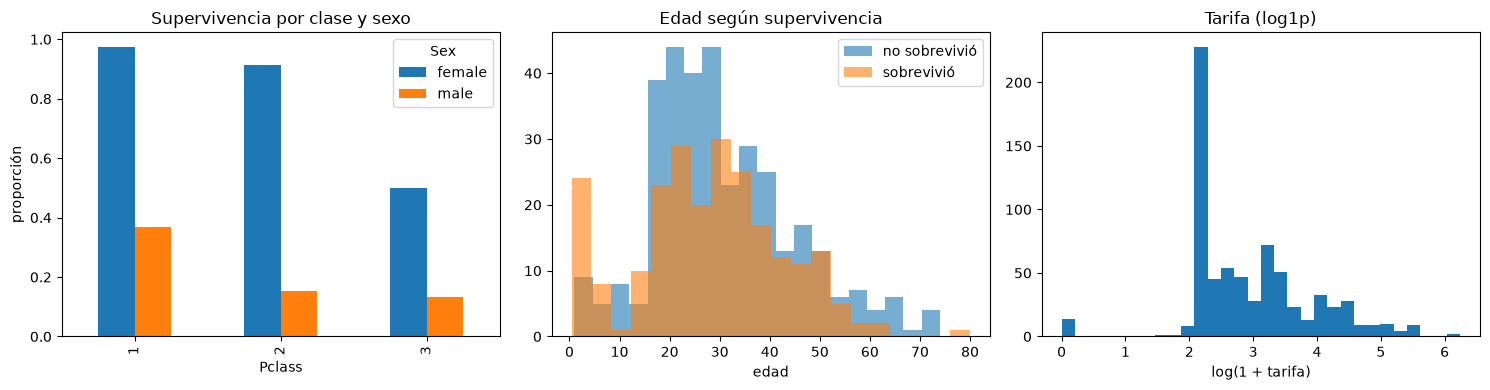

In [3]:
import matplotlib.pyplot as plt

ent = X_ent.assign(Survived=y_ent)

for col in ["Sex", "Pclass", "Embarked"]:
    print(f"Supervivencia por {col}:")
    print(ent.groupby(col)["Survived"].agg(tasa="mean", n="count").round(3), "\n")

print("Supervivencia por sexo y clase:")
print(ent.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean").round(3), "\n")

edad = pd.cut(ent["Age"], [0, 12, 18, 40, 60, 100])
print("Supervivencia por tramo de edad:")
print(ent.groupby(edad, observed=True)["Survived"].agg(tasa="mean", n="count").round(3), "\n")

print("Supervivencia con edad conocida (False) o faltante (True):")
print(ent.groupby(ent["Age"].isna())["Survived"].agg(tasa="mean", n="count").round(3), "\n")

familia = (ent["SibSp"] + ent["Parch"]).clip(upper=4)
print("Supervivencia por familiares a bordo (4 = 4 o más):")
print(ent.groupby(familia)["Survived"].agg(tasa="mean", n="count").round(3), "\n")

print("Variables numéricas:")
print(ent[NUM].describe().round(2).T)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ent.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean").plot.bar(ax=ax[0])
ax[0].set(title="Supervivencia por clase y sexo", ylabel="proporción")
for s, g in ent.groupby("Survived"):
    ax[1].hist(g["Age"].dropna(), bins=20, alpha=0.6, label="sobrevivió" if s else "no sobrevivió")
ax[1].set(title="Edad según supervivencia", xlabel="edad"); ax[1].legend()
ax[2].hist(np.log1p(ent["Fare"]), bins=30)
ax[2].set(title="Tarifa (log1p)", xlabel="log(1 + tarifa)")
plt.tight_layout(); plt.show()

### Conclusiones del Bloque 3

- El sexo es la variable que más separa (74,3 % de las mujeres sobrevive frente al 18,5 % de los hombres) y actúa junto con la clase: las mujeres de primera y segunda sobreviven un 97,5 % y 91,4 %, las de tercera un 50,0 %; los hombres, 37,0 %, 15,2 % y 13,5 %. Un modelo lineal necesita un término de interacción para captarlo.
- La clase importa en la dirección esperada (64,9 %, 44,7 % y 24,3 %). El puerto también se asocia con la supervivencia (Cherburgo 56,1 %, Queenstown 43,6 %, Southampton 32,8 %), pero probablemente por la composición de clases en cada puerto, que no se ha comprobado: no se lee como causa.
- Los de 12 años o menos sobreviven más (60,0 %, 55 pasajeros); la cifra de los mayores de 60 (18,8 %) se apoya en solo 16 pasajeros.
- Que falte la edad se asocia con menor supervivencia (29,2 % frente a 40,5 %), así que el imputador añade un indicador de dato faltante.
- La relación con los familiares a bordo no es monótona (30,0 % con 0, hasta 72,7 % con 3, 16,0 % con 4 o más): un coeficiente lineal la capta mal.
- `Fare` tiene una cola larga (media 31,8, mediana 14,5, máximo 512,3) y valores en 0: se transforma con `log1p` antes de escalar.
- Las figuras de este bloque no se revisaron en la terminal; las cifras salen de las tablas.

## Bloque 4: comparación de modelos (validación cruzada solo en entrenamiento)

Se comparan cinco candidatos con 5 folds estratificados y semilla fija. Todo el preprocesado va dentro del Pipeline, de modo que imputación, escalado y codificación se ajustan solo con el entrenamiento de cada fold, y solo se usan componentes de scikit-learn para poder guardar el modelo y cargarlo desde la aplicación.

**Regla de elección, fijada antes de ver los resultados:** gana el modelo con mayor F1 medio de los supervivientes. Si otro queda a menos de una desviación estándar del mejor, se elige el más sencillo, en este orden: logística, logística con interacciones, random forest, gradient boosting.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder,
                                   FunctionTransformer, PolynomialFeatures)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def preprocesado(interacciones=False):
    pasos_cat = [("imp", SimpleImputer(strategy="most_frequent")),
                 ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
    if interacciones:
        pasos_cat.append(("int", PolynomialFeatures(2, interaction_only=True, include_bias=False)))
    return ColumnTransformer([
        ("edad", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                           ("esc", StandardScaler())]), ["Age"]),
        ("tarifa", Pipeline([("log", FunctionTransformer(np.log1p)),
                             ("esc", StandardScaler())]), ["Fare"]),
        ("fam", StandardScaler(), ["SibSp", "Parch"]),
        ("cat", Pipeline(pasos_cat), CAT)])

candidatos = {
    "Línea base": Pipeline([("pre", preprocesado()), ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Logística": Pipeline([("pre", preprocesado()), ("clf", LogisticRegression(max_iter=1000))]),
    "Logística + interacciones": Pipeline([("pre", preprocesado(True)), ("clf", LogisticRegression(max_iter=1000))]),
    "Random forest": Pipeline([("pre", preprocesado()), ("clf", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, random_state=SEED))]),
    "Gradient boosting": Pipeline([("pre", preprocesado()), ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
}

metricas = {"accuracy": "accuracy", "f1": "f1", "auc": "roc_auc"}
filas = []
for nombre, modelo in candidatos.items():
    r = cross_validate(modelo, X_ent, y_ent, cv=cv, scoring=metricas)
    fila = {"modelo": nombre}
    fila.update({f"{k} (media)": r[f"test_{k}"].mean() for k in metricas})
    fila["f1 (desv.)"] = r["test_f1"].std()
    filas.append(fila)
print(pd.DataFrame(filas).set_index("modelo").round(3))

                           accuracy (media)  f1 (media)  auc (media)  \
modelo                                                                 
Línea base                            0.617       0.000        0.500   
Logística                             0.788       0.713        0.857   
Logística + interacciones             0.794       0.699        0.862   
Random forest                         0.812       0.737        0.876   
Gradient boosting                     0.824       0.761        0.876   

                           f1 (desv.)  
modelo                                 
Línea base                      0.000  
Logística                       0.023  
Logística + interacciones       0.020  
Random forest                   0.039  
Gradient boosting               0.034  


### Conclusiones del Bloque 4

- Todos los modelos superan con claridad la línea base (accuracy 0,617). Los de árboles rinden más que los lineales, algo esperable por la relación no lineal con los familiares y la interacción de sexo y clase.
- Por la regla fijada de antemano, el elegido es random forest (F1 0,737 ± 0,039): el mejor F1 es gradient boosting (0,761 ± 0,034), pero el random forest queda dentro de una desviación estándar y es más sencillo. No gana: la diferencia de F1 (0,024) es menor que la desviación entre folds, y el AUC es idéntico (0,876).
- La logística con interacciones sube un poco el AUC (0,862 frente a 0,857) pero baja el F1, así que las interacciones aportan poco al modelo lineal.
- La logística (F1 0,713) queda a 0,014 del umbral de la regla. Es la opción más interpretable y la diferencia con el random forest no es grande.

## Bloque 5: ajuste del random forest (solo entrenamiento)

Búsqueda en rejilla de 32 combinaciones con los mismos 5 folds, optimizando el F1 de los supervivientes.

**Regla de elección, fijada antes de ver los resultados:** entre las combinaciones dentro de una desviación estándar del mejor F1, gana la de menor profundidad y, a igualdad, la de mayor `min_samples_leaf`. A igual rendimiento se prefiere el modelo más simple.

In [5]:
from sklearn.model_selection import GridSearchCV

base = Pipeline([("pre", preprocesado()),
                 ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED))])
rejilla = {"clf__max_depth": [3, 5, 8, None],
           "clf__min_samples_leaf": [1, 3, 5, 10],
           "clf__max_features": ["sqrt", 0.5]}
gs = GridSearchCV(base, rejilla, scoring="f1", cv=cv, refit=False, n_jobs=-1)
gs.fit(X_ent, y_ent)

res = pd.DataFrame(gs.cv_results_)[["param_clf__max_depth", "param_clf__min_samples_leaf",
                                    "param_clf__max_features", "mean_test_score", "std_test_score"]]
res.columns = ["max_depth", "min_samples_leaf", "max_features", "f1_media", "f1_desv"]
res = res.sort_values("f1_media", ascending=False).reset_index(drop=True)
print(res.head(8).round(3).to_string())

mejor = res.iloc[0]
cerca = res[res["f1_media"] >= mejor["f1_media"] - mejor["f1_desv"]].copy()
cerca["prof"] = cerca["max_depth"].apply(lambda d: 99 if pd.isna(d) else d)
elegido = cerca.sort_values(["prof", "min_samples_leaf", "f1_media"],
                            ascending=[True, False, False]).iloc[0]
print("\nCombinaciones dentro de 1 desv. del mejor:", len(cerca), "de", len(res))
print("Elegida:", elegido[["max_depth", "min_samples_leaf", "max_features"]].to_dict())
print("F1 con valores por defecto (Bloque 4): 0.737 | F1 elegido: %.3f" % elegido["f1_media"])

  max_depth  min_samples_leaf max_features  f1_media  f1_desv
0      None                 3          0.5     0.750    0.029
1         8                 1          0.5     0.747    0.037
2         5                 1         sqrt     0.744    0.038
3         5                 3         sqrt     0.740    0.034
4         8                 3          0.5     0.738    0.038
5         5                 1          0.5     0.738    0.042
6      None                 1          0.5     0.738    0.030
7      None                 3         sqrt     0.737    0.039

Combinaciones dentro de 1 desv. del mejor: 22 de 32
Elegida: {'max_depth': 3, 'min_samples_leaf': 5, 'max_features': 0.5}
F1 con valores por defecto (Bloque 4): 0.737 | F1 elegido: 0.728


### Conclusiones del Bloque 5

- El mejor F1 de la rejilla (0,750 ± 0,029) supera a los valores por defecto (0,737) en 0,013, menos que la desviación entre folds. El ajuste no aporta una mejora demostrable.
- La rejilla no distingue entre 22 de las 32 combinaciones (están dentro de una desviación del mejor), así que decide la regla de menor profundidad fijada de antemano.
- La combinación elegida (`max_depth=3`, `min_samples_leaf=5`, `max_features=0,5`) tiene F1 0,728, algo por debajo de los valores por defecto. La diferencia también cae dentro del ruido, y a cambio el modelo es mucho más simple y se sobreajusta menos.

## Bloque 6: evaluación final en prueba y guardado del modelo

Se entrena el modelo elegido con todo el conjunto de entrenamiento y se evalúa **una sola vez** en el conjunto de prueba. Después no se vuelve a modificar el modelo. Se guarda con `joblib` y se comprueba que al recargarlo da exactamente las mismas probabilidades.

In [6]:
import joblib
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

modelo = Pipeline([("pre", preprocesado()),
                   ("clf", RandomForestClassifier(n_estimators=300, max_depth=3,
                                                  min_samples_leaf=5, max_features=0.5,
                                                  random_state=SEED))])
modelo.fit(X_ent, y_ent)

pred = modelo.predict(X_test)
proba = modelo.predict_proba(X_test)[:, 1]
print("Prueba (%d filas): accuracy %.3f | F1 %.3f | AUC %.3f"
      % (len(y_test), accuracy_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, proba)))
print("Linea base (todos no sobreviven): %.3f" % (1 - y_test.mean()))
print(pd.DataFrame(confusion_matrix(y_test, pred),
                   index=["real 0", "real 1"], columns=["pred 0", "pred 1"]))

raiz = Path(RUTA).resolve().parents[2]
destino = raiz / "models" / "titanic_rf.joblib"
joblib.dump(modelo, destino)
recargado = joblib.load(destino)
print("Guardado en:", destino.relative_to(raiz))
print("Recarga identica:", bool((recargado.predict_proba(X_test)[:, 1] == proba).all()))

Prueba (179 filas): accuracy 0.788 | F1 0.694 | AUC 0.830
Linea base (todos no sobreviven): 0.615
        pred 0  pred 1
real 0      98      12
real 1      26      43
Guardado en: models/titanic_rf.joblib
Recarga identica: True


### Conclusiones del Bloque 6

- El modelo supera con claridad la línea base (accuracy 0,788 frente a 0,615), pero queda algo por debajo de la validación cruzada (F1 0,694 en prueba frente a 0,728 en validación). Con solo 69 supervivientes en la prueba esa diferencia está dentro del azar esperable, y no se modificó nada tras ver la prueba.
- Es un modelo prudente: detecta el 62 % de los supervivientes (recall 0,62) y cuando dice que sobrevive acierta el 78 % de las veces (precisión 0,78). Falla más dejando pasar supervivientes (26) que dando falsas alarmas (12).
- Todas las cifras tienen bastante margen de error por el tamaño de la prueba (179 filas), y los datos son de un único barco en 1912. El modelo describe patrones históricos y no sirve para predecir nada real.
- El modelo guardado en `models/titanic_rf.joblib` recarga con probabilidades idénticas, así que está listo para usarse en la app.

## Bloque 7: archivos para la app

La app de Streamlit se despliega desde la carpeta `src`, así que el modelo y los límites de los controles se guardan dentro de ella. Los rangos salen de los datos de entrenamiento, no de números elegidos a mano, y se anota la versión de scikit-learn para fijarla en los requisitos de la app.

In [7]:
import json
import sklearn

limites = {col: {"min": float(X_ent[col].min()), "max": float(X_ent[col].max()),
                 "mediana": float(X_ent[col].median())}
           for col in ["Age", "SibSp", "Parch", "Fare"]}
limites["Pclass"] = sorted(int(v) for v in X_ent["Pclass"].unique())
limites["Sex"] = sorted(X_ent["Sex"].unique().tolist())
limites["Embarked"] = sorted(X_ent["Embarked"].dropna().unique().tolist())
limites["supervivencia_entrenamiento"] = float(y_ent.mean())

carpeta_app = raiz / "src" / "model"
carpeta_app.mkdir(exist_ok=True)
joblib.dump(modelo, carpeta_app / "titanic_rf.joblib")
(carpeta_app / "limites.json").write_text(json.dumps(limites, indent=2, ensure_ascii=False))

print(json.dumps(limites))
print("scikit-learn", sklearn.__version__)

{"Age": {"min": 0.42, "max": 80.0, "mediana": 28.5}, "SibSp": {"min": 0.0, "max": 8.0, "mediana": 0.0}, "Parch": {"min": 0.0, "max": 6.0, "mediana": 0.0}, "Fare": {"min": 0.0, "max": 512.3292, "mediana": 14.4542}, "Pclass": [1, 2, 3], "Sex": ["female", "male"], "Embarked": ["C", "Q", "S"], "supervivencia_entrenamiento": 0.38342696629213485}
scikit-learn 1.9.1
